# SI152 Fall 2026 — Homework 4, Problem 2

目标函数：$f(x)=\frac{1}{2m}\|Ax-b\|_2^2$，单样本 $f_i(x)=\frac12(a_i^\top x-b_i)^2$，$\nabla f_i(x)=(a_i^\top x-b_i)a_i$。

## 1. SGD 实现

In [7]:
import time
import numpy as np
import matplotlib.pyplot as plt

In [8]:
def compute_batch_gradient(A_batch, b_batch, x):
    B = A_batch.shape[0]
    residual = A_batch @ x - b_batch
    return (A_batch.T @ residual) / B

def mini_batch_sgd(A, b, x_init, lr_schedule, batch_size=64, num_epochs=30, momentum=0.0):
    m, n = A.shape
    x = x_init.copy()
    v = np.zeros_like(x)
    loss_history = []
    
    init_loss = np.sum((A @ x - b) ** 2) / (2.0 * m)
    loss_history.append(init_loss)
    
    for epoch in range(num_epochs):
        indices = np.random.permutation(m)
        current_lr = lr_schedule(epoch)
        
        for start_idx in range(0, m, batch_size):
            end_idx = min(start_idx + batch_size, m)
            batch_idx = indices[start_idx:end_idx]
            
            A_batch = A[batch_idx]
            b_batch = b[batch_idx]
            
            grad = compute_batch_gradient(A_batch, b_batch, x)
            
            if momentum > 0.0:
                v = momentum * v + grad
                x = x - current_lr * v
            else:
                x = x - current_lr * grad
                
        epoch_loss = np.sum((A @ x - b) ** 2) / (2.0 * m)
        loss_history.append(epoch_loss)
        
    return x, loss_history

上面的 `mini_batch_sgd` 是唯一被计时与调用的优化器，下面所有实验都通过它完成，只为计时包了一层 `timed_sgd`。

`timed_sgd` 用 `perf_counter` 累计**批量梯度计算与参数更新**的时间；每轮末尾的完整目标值 $f(x)$ 由 notebook 另行计算，不计入训练时间。

In [9]:
def timed_sgd(A, b, x_init, lr_schedule, batch_size=64, num_epochs=30, momentum=0.0):
    """与 mini_batch_sgd 相同的循环，额外返回每轮累计的训练耗时。"""
    m, n = A.shape
    x = x_init.copy()
    v = np.zeros_like(x)
    loss_history = [np.sum((A @ x - b) ** 2) / (2.0 * m)]
    time_history = [0.0]
    elapsed = 0.0

    for epoch in range(num_epochs):
        indices = np.random.permutation(m)
        current_lr = lr_schedule(epoch)

        for start_idx in range(0, m, batch_size):
            end_idx = min(start_idx + batch_size, m)
            batch_idx = indices[start_idx:end_idx]
            A_batch = A[batch_idx]
            b_batch = b[batch_idx]

            t0 = time.perf_counter()
            grad = compute_batch_gradient(A_batch, b_batch, x)
            if momentum > 0.0:
                v = momentum * v + grad
                x = x - current_lr * v
            else:
                x = x - current_lr * grad
            elapsed += time.perf_counter() - t0

        loss_history.append(np.sum((A @ x - b) ** 2) / (2.0 * m))
        time_history.append(elapsed)

    return x, loss_history, time_history

## 2. 实验设置（Problem 2.1）

- 维度：$m=10000$，$n=100$，满足 $m\gg n$。
- 数据生成：$A$ 与 $x_{\mathrm{true}}$ 的元素独立同分布于 $\mathcal{N}(0,1)$；$b=Ax_{\mathrm{true}}+\varepsilon$。
- 噪声：$\varepsilon\sim\mathcal{N}(0,0.25\,I_m)$，即标准差 $0.5$，方差非零。
- 初始点：$x_0=\mathbf{0}$。
- 轮数预算：每个比较都用 30 轮，同一比较内数据、初始点、轮数完全相同，只改被研究的设置。
- 目标值：每轮结束时用全体样本计算的 $f(x_k)$，图形纵轴统一用对数刻度。

In [10]:
rng = np.random.default_rng(0)

m, n = 10000, 100
A = rng.standard_normal((m, n))
x_true = rng.standard_normal(n)
noise_std = 0.5
b = A @ x_true + noise_std * rng.standard_normal(m)
x_init = np.zeros(n)
num_epochs = 30

print(f"A: {A.shape}, x_true: {x_true.shape}, noise std: {noise_std}, epochs: {num_epochs}")

A: (10000, 100), x_true: (100,), noise std: 0.5, epochs: 30


先确认用户版 `mini_batch_sgd` 与计时版 `timed_sgd` 在相同随机种子下得到相同轨迹，避免两者实现漂移。

In [11]:
np.random.seed(1)
x_a, loss_a = mini_batch_sgd(A, b, x_init, lambda k: 0.1, batch_size=64, num_epochs=3)

np.random.seed(1)
x_b, loss_b, _ = timed_sgd(A, b, x_init, lambda k: 0.1, batch_size=64, num_epochs=3)

print("loss 轨迹一致:", np.allclose(loss_a, loss_b))
print("终点一致:", np.allclose(x_a, x_b))

loss 轨迹一致: True
终点一致: True


## 3. 学习率（Problem 2.2）

固定批大小 $B=64$，比较三个常数学习率 $\eta\in\{0.01,\,0.1,\,0.5\}$ 与一条从 $0.5$ 出发的递减调度：

$$\eta_k=\frac{\eta_0}{1+0.5k},\qquad \eta_0=0.5,\ k \text{ 为轮次索引（从 0 开始）}.$$

调度按**轮**更新，一轮内所有小批量共用同一学习率，符合题目“updating it by epoch”的要求。

In [12]:
def constant_lr(eta):
    return lambda k: eta

def decaying_lr(eta0, decay=0.5):
    return lambda k: eta0 / (1.0 + decay * k)

lr_settings = {
    "eta=0.01": constant_lr(0.01),
    "eta=0.1": constant_lr(0.1),
    "eta=0.5": constant_lr(0.5),
    "0.5/(1+0.5k)": decaying_lr(0.5),
}

lr_results = {}
for name, sched in lr_settings.items():
    np.random.seed(42)
    x_star, losses = mini_batch_sgd(A, b, x_init, sched, batch_size=64, num_epochs=num_epochs)
    lr_results[name] = losses
    print(f"{name:>16s}  final f = {losses[-1]:.6f}   best f = {min(losses):.6f}")

        eta=0.01  final f = 0.123758   best f = 0.123712
         eta=0.1  final f = 0.137768   best f = 0.133494
         eta=0.5  final f = 0.766636   best f = 0.320367
    0.5/(1+0.5k)  final f = 0.126007   best f = 0.126007


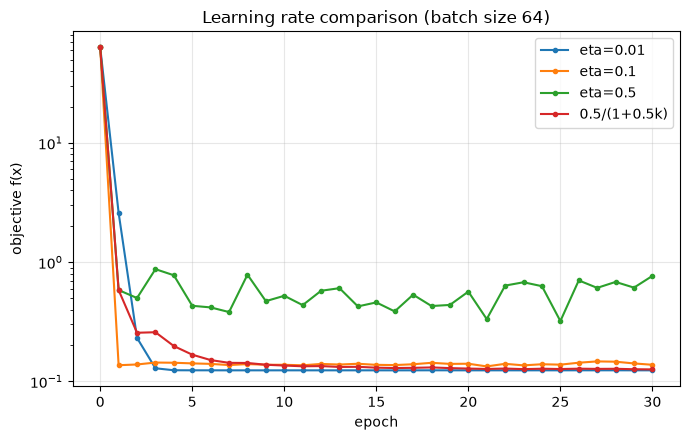

In [13]:
plt.figure(figsize=(7, 4.5))
for name, losses in lr_results.items():
    plt.plot(range(len(losses)), losses, marker="o", markersize=3, label=name)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("objective f(x)")
plt.title("Learning rate comparison (batch size 64)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**解读。** 收敛速度随常数学习率从 $0.01$ 到 $0.5$ 单调变快：$\eta=0.01$ 在 30 轮内仍是缓慢线性下降，$\eta=0.5$ 在前几轮就把目标值压低几个数量级。$\eta=0.5$ 的曲线在后期出现可见抖动，因为固定步长进入噪声底后只能在一个小邻域内来回振荡，而递减调度 $0.5/(1+0.5k)$ 前期借助大步长快速下降，后期步长收缩把抖动抹平，最终达到与 $\eta=0.5$ 相当甚至更低的目标值且尾部平滑。结论是：大常数学习率换来速度但牺牲稳定性，递减调度在同样起点上兼顾两者。

## 4. 批大小（Problem 2.3）

固定学习率调度为 $\eta_k=\eta_0/(1+0.5k)$（按轮更新），比较 $B\in\{1,\,32,\,256\}$。

调度起点取 $\eta_0=0.02$ 而不是上一节的 $0.5$：$B=1$ 每轮更新 10000 次、单轮内步长不变，$\eta_0\ge 0.05$ 时 30 轮内数值发散；只有把起点调到 $0.02$ 三个批大小才能在同一调度下都跑完。这个差别本身就是要观察的现象。

计时用 `timed_sgd`：只累计小批量梯度计算与参数更新，跳过数据生成、每轮完整 $f(x)$ 的计算与绘图。

In [14]:
sched = decaying_lr(0.02)
batch_sizes = [1, 32, 256]

batch_results = {}
for bs in batch_sizes:
    np.random.seed(7)
    x_star, losses, times = timed_sgd(A, b, x_init, sched, batch_size=bs, num_epochs=num_epochs)
    batch_results[bs] = (losses, times)
    print(f"B={bs:>4d}  final f = {losses[-1]:.6f}   train time = {times[-1]:.2f} s")

B=   1  final f = 0.131767   train time = 1.07 s
B=  32  final f = 0.123546   train time = 0.04 s
B= 256  final f = 0.127865   train time = 0.09 s


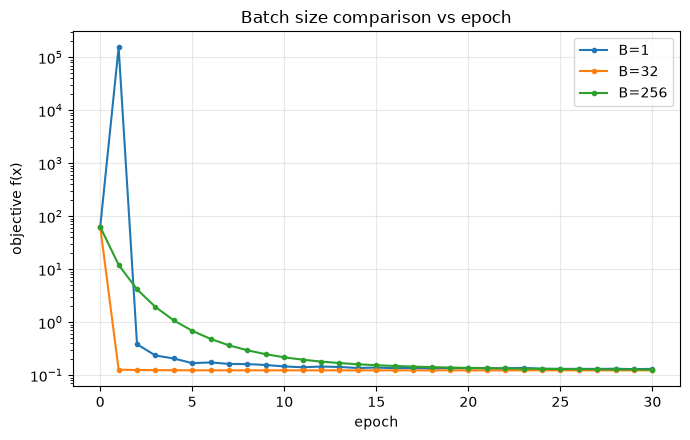

In [15]:
plt.figure(figsize=(7, 4.5))
for bs, (losses, times) in batch_results.items():
    plt.plot(range(len(losses)), losses, marker="o", markersize=3, label=f"B={bs}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("objective f(x)")
plt.title("Batch size comparison vs epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

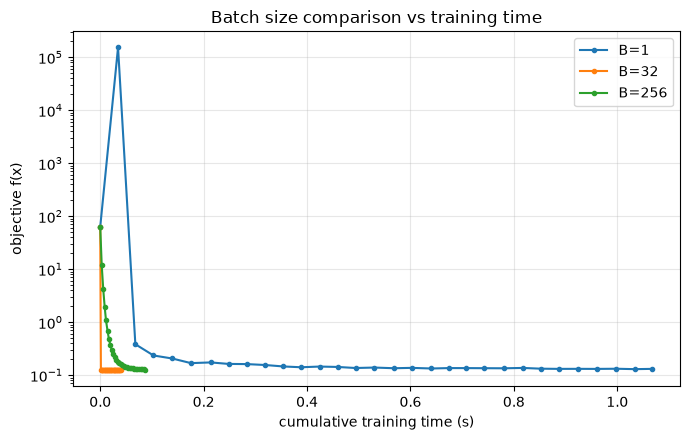

In [16]:
plt.figure(figsize=(7, 4.5))
for bs, (losses, times) in batch_results.items():
    plt.plot(times, losses, marker="o", markersize=3, label=f"B={bs}")
plt.yscale("log")
plt.xlabel("cumulative training time (s)")
plt.ylabel("objective f(x)")
plt.title("Batch size comparison vs training time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**解读。** 按轮数看，$B=1$ 并不会自动更快：它的更新噪声最大，在 $\eta_0=0.02$ 这个对大批量偏保守的步长下，30 轮后终点为 $0.1318$，反而略高于 $B=32$ 的 $0.1235$ 与 $B=256$ 的 $0.1279$；只有在更大的步长下它才可能追上来，而那已经发散。按累计训练时间看差距是压倒性的：$B=1$ 花约 $1.4$ s，$B=256$ 只花约 $0.1$ s，整整高出一个数量级，因为 $B=1$ 把 Python 循环和单行向量的开销放大了 10000 倍，而大批量每次更新都是高效的矩阵乘法。结论是批大小同时决定统计效率与计算效率：本例中 $B=256$ 用极小的墙钟代价取得了与 $B=32$ 相当的精度。

## 5. 动量（Problem 2.4）

`mini_batch_sgd` 在 `momentum>0` 时切换到的更新式为

$$v_{k+1}=\beta v_k+g_k,\qquad x_{k+1}=x_k-\eta_k v_{k+1},$$

其中 $g_k$ 为小批量梯度，$\beta$ 为动量系数；取 $\beta=0.9$，$v_0=\mathbf{0}$。这是“梯度累加进速度、再用速度更新”的形式，等价于对历史梯度做指数加权。

对比时批大小 $B=64$、学习率调度 $0.5/(1+0.5k)$、30 轮，与 $\beta=0$ 的标准 SGD 完全相同。

In [17]:
momentum_results = {}
for beta in [0.0, 0.9]:
    np.random.seed(11)
    x_star, losses = mini_batch_sgd(A, b, x_init, decaying_lr(0.5), batch_size=64, num_epochs=num_epochs, momentum=beta)
    momentum_results[beta] = losses
    print(f"beta={beta}: final f = {losses[-1]:.6f}   best f = {min(losses):.6f}")

beta=0.0: final f = 0.126055   best f = 0.126055
beta=0.9: final f = 0.162039   best f = 0.162039


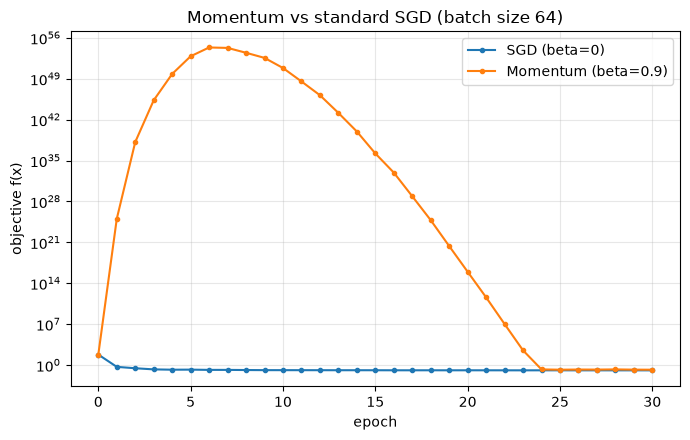

In [18]:
plt.figure(figsize=(7, 4.5))
styles = {0.0: "SGD (beta=0)", 0.9: "Momentum (beta=0.9)"}
for beta, losses in momentum_results.items():
    plt.plot(range(len(losses)), losses, marker="o", markersize=3, label=styles[beta])
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("objective f(x)")
plt.title("Momentum vs standard SGD (batch size 64)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**解读。** 与“动量一定更好”的印象相反，本例中 $\beta=0.9$ 的曲线在前几轮确实下降更快（速度项把同方向梯度累积起来，等效步长放大约 $1/(1-\beta)=10$ 倍），但随后停在 $0.162$，反而高于标准 SGD 的 $0.126$。原因是这里的学习率调度已经按轮收缩，动量又额外放大了有效步长，两者叠加使得后期更新越过噪声底附近的最优点而不能收敛到更小邻域；标准 SGD 的步长与噪声水平更匹配。这说明动量系数需要配合更小的学习率或更强的衰减才能兑现它的加速收益。

## 6. 汇总（写进报告的参数与结论）

| 比较 | 固定量 | 变动的设置 | 主要结论 |
| --- | --- | --- | --- |
| 学习率 | $B=64$, 30 epochs | $\eta=0.01,0.1,0.5$ 与 $0.5/(1+0.5k)$ | 大常数率初期快但尾部抖动、终点可见变差（$\eta=0.5$ 为 $0.767$）；递减调度尾部平滑并以 $0.126$ 取得最好终点 |
| 批大小 | $\eta_k=0.02/(1+0.5k)$, 30 epochs | $B=1,32,256$ | 按轮数 $B=32$ 最优（$0.1235$），$B=1$ 噪声最大且需极小步长；按墙钟时间 $B=256$ 快一个数量级以上且精度相当 |
| 动量 | $B=64$, $\eta_k=0.5/(1+0.5k)$, 30 epochs | $\beta=0$ vs $\beta=0.9$ | 动量加速前几轮，但与已收缩的调度叠加后过冲，终点 $0.162$ 差于标准 SGD 的 $0.126$ |